# Chapter 1: Introduction and Motivation

*Machine learning and quantum computing can be combined in four ways, according to whether the data and the computer are classical or quantum; this book is mainly about classical data processed by a quantum computer, the setting of the quantum support-vector machine, the quantum neural network and the quantum approximate optimization algorithm. The chapter recalls what machine learning is, defines a quantum machine-learning model as a parametrized circuit with a data-dependent encoding and a measurement, and examines the three properties of quantum mechanics usually invoked in its favor, the size of the state space, interference and entanglement, together with the two kinds of speedup claim in the literature and the conditions they rest on. The challenges of near-term hardware, shot noise, data encoding, barren plateaus and fair benchmarking are set out, and the current reassessment of variational circuits is presented: their trainability limits, the classical surrogates that compete with them, the total cost of encoding and measurement, and the evidence that the clearest advantages concern quantum rather than classical data. A table maps the chapters of the companion volume, and of the author's machine-learning and many-body texts, to their use here. The basis, angle and amplitude encodings are introduced with a program on the book's own simulator, and the plan of the book, its conventions and its software are described.*


<!-- Macro definitions for MathJax, mirroring book.tex -->
$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
\newcommand{\matr}[1]{\boldsymbol{#1}}
\newcommand{\bfv}[1]{\boldsymbol{#1}}
\renewcommand{\vec}[1]{\boldsymbol{#1}}
\newcommand{\uvec}[1]{\boldsymbol{\hat{#1}}}
\newcommand{\op}[1]{\widehat{#1}}
\newcommand{\Op}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\OP}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\Det}[1]{|\boldsymbol{#1}|}
\newcommand{\bigO}{\mathcal{O}}
\newcommand{\var}{\mathrm{Var}}
\newcommand{\cov}{\mathrm{Cov}}
\newcommand{\real}[1]{\mathrm{Re}\left\{#1\right\}}
\newcommand{\ud}[1]{d#1}
\newcommand{\udd}[1]{d^2#1}
\newcommand{\mean}[1]{\langle #1 \rangle}
\newcommand{\overlap}[2]{\langle #1 | #2 \rangle}
\newcommand{\bracket}[3]{\langle #1 | #2 | #3 \rangle}
\newcommand{\projection}[2]{| #1 \rangle \langle #2 |}
\newcommand{\brab}[1]{\big\langle #1 \big|}
\newcommand{\ketb}[1]{\big| #1 \big\rangle}
\newcommand{\bket}[1]{\vert #1\rangle}
\newcommand{\bbra}[1]{\langle #1\vert}
\newcommand{\ketbra}[2]{\vert #1\rangle\langle #2\vert}
\newcommand{\braket}[2]{\langle #1\vert #2\rangle}
$$

In [1]:
# Put every BookPrograms/chapter*/ and BookPrograms/common/ on sys.path
import sys, pathlib
root = pathlib.Path.cwd().resolve()
while not (root / 'BookPrograms').is_dir() and root.parent != root:
    root = root.parent
sys.path[:0] = [str(p) for p in (root / 'BookPrograms').iterdir() if p.is_dir()]
import numpy as np


## Two fields and a question

Machine learning and quantum computing are the two computational
developments of the last decades that have changed what physicists
expect a computer to do. The first has turned the fitting of functions
to data, an activity as old as least squares, into a technology that
recognizes images, translates languages, predicts the folding of
proteins and, closer to the subjects of this book, represents the
ground states of many-body Hamiltonians by neural networks and
emulates expensive simulations by surrogate models. The second has
produced, after forty years of theory, machines of a few hundred
qubits on which short circuits can be run, and a catalog of
algorithms, among them phase estimation, Hamiltonian simulation and
the variational quantum eigensolver, which the companion volume
*Quantum Computing for Many-body Physics* [QCbook] develops
for the many-body problem. It was inevitable that the two would be
combined, and *quantum machine learning* (QML) is the name of the
combination [Biamonte2017,Schuld2015,SchuldPetruccione2021].
This book is the second half of that story and was written to be read
after the first: the companion volume is the material of the first
half of a one-semester course on quantum computing and quantum machine
learning, and the present chapters are the second half. They use its
qubits, gates, measurements, Hamiltonians and variational algorithms
as background without rederiving them.
Section *Relation to the companion volume* says precisely which parts.

The combination can be made in four ways, and it is worth being clear
from the start which of them this book is about. The data can be
classical, such as the pixels of an image, the features of a flower or
the measured properties of a material, or quantum, such as the state
of a register prepared by a quantum simulation; and the computer that
processes the data can be classical or quantum. Classical data on a
classical computer is ordinary machine learning. Quantum data on a
classical computer is what the neural-network quantum states and
Monte Carlo methods of many-body physics have done for a decade, with
the state represented classically. Quantum data on a quantum computer
is the most natural pairing, and the one where the strongest arguments
for an advantage exist, because the data are already in the form the
machine works with and no loading step is needed. The bulk of this
book, and all of Chapters 2, 3
and 4, concerns the remaining case, *classical data
on a quantum computer*: the classical input $\vec{x}$ is written into
the state of a register by a data-dependent circuit, a parametrized
circuit processes it, and a measurement returns the prediction. This
is the setting of the quantum support-vector machine, the quantum
neural network and the quantum approximate optimization algorithm, it
is the setting in which the first experiments on real hardware have
been performed, and it is also the setting in which the claims of
quantum advantage must be read most carefully. Chapter 5
on quantum Boltzmann machines, whose model is a Hamiltonian and whose
samples come from its thermal state, is the point of the book where
the quantum-data case is approached.

The question that runs through the book is a simple one.
A quantum computer with $n$ qubits has a state space of $2^n$
dimensions, which is more than any classical feature space a machine
could afford to work in explicitly. Does this give a learning
algorithm anything that a classical algorithm cannot have? The honest
answer, developed from Section *Why quantum?* onwards, is
"sometimes, under conditions that are easy to state and hard to
meet", and the purpose of the book is to put the reader in a position
to judge for themselves, with the mathematics written out and with
programs that run.


## What machine learning is

Machine learning is the study of algorithms whose performance on a
task improves with data. The data are a set of *samples*, each
a vector $\vec{x}\in\mathbb{R}^d$ of $d$ *features*, and the
task is specified by what, if anything, accompanies each sample.

- In *supervised learning* every sample comes with a label
   $y$, a class ($y=\pm1$ for the binary classification problems of
   Chapter 2) or a real number (regression), and the
   algorithm must predict the label of samples it has not seen.
- In *unsupervised learning* there are no labels, and the
   algorithm must find structure in the samples themselves: clusters, a
   low-dimensional description, or a probability distribution from which
   the samples could have been drawn. The Boltzmann machines of
   Chapter 5 are models of this kind.
- In *reinforcement learning* the algorithm is an agent that
   acts in an environment and receives rewards, and it must learn a
   policy that maximizes the reward over time. Chapter 6 is
   reserved for it and its quantum versions.

Whatever the task, the workflow is the same and is drawn in
Fig. 1.1: a *model* $f(\vec{x};\vec{\theta})$
with adjustable parameters $\vec{\theta}$ is chosen, a *cost*
(or loss) function $\mathcal{L}(\vec{\theta})$ measures how badly the model does
on the training data, an *optimizer* moves the parameters so as
to reduce the cost, and the trained model is finally judged on
*test* data it was not trained on. The last step is the one that
distinguishes learning from curve fitting: a model that reproduces
the training data perfectly and the test data badly has
*overfitted*, and most of the practical art of the field, from
regularization to the choice of model class, is about avoiding that.

![The workflow of a hybrid quantum-classical learning model. The three r](../../BookFigures/chapter1/1-workflow.png)

*Figure 1.1: The workflow of a hybrid quantum-classical learning model. The three red boxes run on the quantum computer: a data-dependent circuit $U(\vec{x})$ loads a sample, a parametrized circuit $W(\vec{\theta})$ processes it, and a measurement returns a number. Everything else, the cost that compares the output with the label and the optimizer that updates $\vec{\theta}$, is classical. In a kernel method (Chapter 2) the box $W(\vec{\theta})$ is absent and the measurement returns an overlap instead.*

Two families of supervised models will matter for us. The first,
*kernel methods*, of which the support-vector machine of
Chapter 2 is the best-known member, never work with the
features themselves but only with a similarity $K(\vec{x},\vec{x}')$
between pairs of samples; the model is a weighted sum of similarities
to the training points, $f(\vec{x})=\sum_i\lambda_i y_i K(\vec{x}_i,\vec{x})+b$,
and training is a convex optimization problem with a unique solution.
The second, *neural networks*, compose simple parametrized maps
into a deep function whose parameters are found by gradient descent on
a non-convex cost. The quantum models of this book fall into the same
two families, and one of the lessons of Chapter 2, due to
Schuld [Schuld2021kernel], is that the division is less sharp than
it looks: every quantum model of the form of Fig. 1.1
is a linear model in the space of density matrices, and can therefore
be written as a kernel machine. The standard references for the
classical material are the books of Hastie, Tibshirani and Friedman
[Hastie2009], Bishop [Bishop2006] and Goodfellow, Bengio and
Courville [Goodfellow2016], and, closest to this book in notation,
programs and outlook, the author's *Machine Learning and the
Physical Sciences* [MLbook], whose chapters on optimization,
support-vector machines, neural networks, neural networks for
differential equations, Boltzmann machines and reinforcement learning
are the classical halves of Chapters 2, 4,
5 and 6; we assume the reader has met linear
regression, gradient descent and the idea of a training and a test
set, and we derive everything else that we need.


## What quantum machine learning is

In the setting of this book a quantum machine-learning model is a
function from a classical input to a real number, computed as the
expectation value of an observable in a state prepared by a circuit
that depends on the input and on parameters:

$$
f(\vec{x};\vec{\theta})=\langle 0\vert\, U^{\dagger}(\vec{x})\,W^{\dagger}(\vec{\theta})\,\hat{O}\,W(\vec{\theta})\,U(\vec{x})\,\vert 0\rangle .\tag{1.1}
$$

Here $\vert 0\rangle=\vert 0\rangle^{\otimes n}$ is the initial state
of $n$ qubits, $U(\vec{x})$ is the *encoding* or *feature
map* circuit that writes the sample into the register, $W(\vec{\theta})$
is a parametrized circuit, and $\hat{O}$ is a Hermitian operator,
usually a single Pauli $Z$ or a product of them, whose expectation
value is estimated by repeating the circuit and averaging the
measurement outcomes. Every model in Chapters 2
to 4 is a special case of Eq. (1.1).

- The *quantum support-vector machine* of
   Chapter 2 has no trainable $W$ at all. Its output is the overlap
   of two encoded states, $K(\vec{x},\vec{x}')=\vert\langle 0\vert U^{\dagger}(\vec{x})U(\vec{x}')\vert 0\rangle\vert^2$,
   which is Eq. (1.1) with $\hat{O}=\vert 0\rangle\langle 0\vert$
   and $U^{\dagger}(\vec{x}')$ in the place of $W$; the quantum computer supplies a
   kernel and a classical support-vector machine does the learning.
- The *quantum approximate optimization algorithm* of
   Chapter 3 encodes the problem rather than a sample: the
   data, a graph or a cost matrix, define a diagonal Hamiltonian $H_C$,
   $W(\vec{\theta})$ alternates $e^{-i\gamma H_C}$ with a mixing term, and
   $\hat{O}=H_C$ itself.
- The *quantum neural network* or variational quantum
   classifier of Chapter 4 is Eq. (1.1) as it
   stands, with layers of rotations and entangling gates in
   $W(\vec{\theta})$ and the sign of $f$ as the predicted class; its
   parameters are trained by gradient descent, with gradients that the
   quantum computer itself can evaluate exactly by the parameter-shift
   rule [Mitarai2018,Schuld2019gradients].
- The *quantum Boltzmann machine* of Chapter 5
   replaces the pure state by the thermal state $e^{-\beta H(\vec{\theta})}/Z$
   of a parametrized Hamiltonian, and its training adjusts $H$ so that
   the measurement statistics of the thermal state match those of the
   data.

The quantum computer, in all four, is used as a device that prepares a
state in a $2^n$-dimensional space and estimates expectation values in
it; the learning, the comparison with the labels and the update of the
parameters, is classical. This is the *hybrid* architecture of
Fig. 1.1, the same architecture as the variational
quantum eigensolver, and the reader who knows VQE from the companion
volume [QCbook] will recognize every piece of it: the ansatz is
$W(\vec{\theta})$, the Hamiltonian is $\hat{O}$, and the only new
element is the encoding $U(\vec{x})$, which makes the circuit depend on
data. That element turns out to be decisive; Schuld's remark that
"the way that data is encoded into quantum states is the main
ingredient that can potentially set quantum models apart from
classical machine learning models" [Schuld2021kernel] could serve
as the motto of the whole book.


## Why quantum?

Three properties of quantum mechanics are usually invoked, and it
pays to state exactly what each does and does not give.

**The size of the state space.** 
The state of $n$ qubits is a vector of $2^n$ complex amplitudes. An
encoding circuit $U(\vec{x})$ therefore maps a $d$-dimensional sample
into a $2^n$-dimensional feature space, and the overlap of two encoded
states is an inner product in that space: this is a kernel, and a
kernel is exactly what a support-vector machine needs. The analogy
with the classical kernel trick, where a polynomial or Gaussian
kernel evaluates an inner product in a high- or infinite-dimensional
space without ever constructing the feature vectors, is exact, and
Chapter 2 makes it precise. What the size of the space
does *not* give is a free lunch: a classical computer can also
work in a $2^n$-dimensional space implicitly, through the kernel, and
the question is whether the particular inner product that the quantum
circuit computes is useful for the data at hand and hard to compute
classically. Both conditions are needed, and the second is only known
to hold for feature maps built from problems, such as the discrete
logarithm, that are believed to be classically intractable [Liu2021].

**Interference.** 
Amplitudes add before probabilities are taken, so a circuit can
arrange for wrong answers to cancel and right ones to reinforce. This
is what makes quantum algorithms faster than classical ones when they
are, and it is what the quantum Fourier transform exploits: the
discrete Fourier transform of $N$ numbers costs $\bigO(N^2)$
operations, the fast Fourier transform $\bigO(N\log N)$, and the
quantum Fourier transform $\bigO(\log^2 N)$ gates on $\log_2 N$
qubits [NielsenChuang2010]. The last figure is the one usually
quoted and the one that needs reading twice: the transform is applied
to amplitudes, which must first be loaded and cannot afterwards be
read out one by one, so the exponential saving is real only for
problems in which the input is already a quantum state and the output
is a single number or a sample. Phase estimation, which the companion
volume uses to compute eigenvalues, is such a problem. Transforming a
classical signal is not.

**Entanglement.** 
A product state of $n$ qubits is described by $2n$ real parameters,
an entangled one by up to $2^{n+1}-2$. Entangling gates in
$U(\vec{x})$ therefore produce feature maps whose kernels do not
factorize into one-dimensional pieces, and this is where a quantum
kernel can differ from any classical kernel that is cheap to evaluate.
The angle encoding of Section *Loading classical data into qubits*, which puts one
feature on one qubit and entangles nothing, has a kernel that is a
product of cosines (Exercise 1.2) and is simulated by a
classical computer in $\bigO(d)$ operations; the entangling feature
map of Havlíček *et al.* [Havlicek2019] has a kernel
that, for enough qubits, no known classical method evaluates
efficiently. Chapter 2 runs both.

**The speedup claims.** 
Two kinds of claim appear in the literature, and they are made for
different machines. The first, due to Rebentrost, Mohseni and Lloyd
[Rebentrost2014], applies the quantum linear-systems algorithm of
Harrow, Hassidim and Lloyd [HHL2009] to the equations that train
a least-squares support-vector machine, and obtains a running time
polylogarithmic in the number of samples $N$ and the number of features
$d$. The result is correct and the assumptions are severe: the data
must be available in a quantum random-access memory
[Giovannetti2008] that loads a vector of $N$ entries in
$\bigO(\log N)$ time, the kernel matrix must be well conditioned, and
the output is a quantum state from which only a few numbers can be
extracted. Aaronson's "read the fine print" [Aaronson2015] is the
reference on these conditions, and Tang's dequantization of the
recommendation-systems algorithm [Tang2019] showed that, once the
same data-access assumptions are granted to a classical algorithm, the
exponential advantage of several of these proposals disappears. The
second kind of claim makes no promise about running time at all. It
concerns the *near-term* or NISQ machines [Preskill2018] of
the present decade, estimates the kernel or runs the variational
circuit on them, and asks only whether the resulting model can learn
something that classical models cannot. The answer is known to be yes
for carefully constructed problems [Liu2021], is known to depend
on the data rather than on the model [Huang2021], and is open for
the data sets one actually meets. Everything in
Chapters 2 to 4 is of the second kind, and
we try to say in each case what was gained and what was not.


## Challenges

The reasons that quantum machine learning is a research field rather
than a product are the same reasons that the companion volume gives
for every near-term algorithm, with two additions, data encoding and
fair benchmarking, that are specific to learning.

**Hardware.** 
The qubits of today's machines decohere in microseconds to
milliseconds, two-qubit gates fail at the level of $10^{-3}$ to
$10^{-2}$, and circuits must therefore be shallow. A model whose
accuracy depends on a deep entangling feature map, or on many layers
of $W(\vec{\theta})$, cannot be run as written. Every result in this book
is obtained on a classical state-vector simulator of our own, in
which the state never decoheres, and the chapters say where a real
device would differ.

**Shot noise.** 
Every number a quantum computer returns is an estimate from a finite
number $S$ of repetitions, with a statistical error that falls only as
$1/\sqrt{S}$. For a kernel method this means that every entry of the
$N\times N$ kernel matrix is noisy, and Section *Kernels from a finite number of shots* shows
what that does to the classifier; for a variational model it means
that every gradient component is noisy, and the optimizer must be one
that tolerates that.

**Data encoding.** 
A quantum computer cannot read a file. Every sample has to be written
into the register by a circuit, and the choice of that circuit, taken
up in Section *Loading classical data into qubits* and throughout
Chapter 2, is both the main design freedom of a quantum
model and its main cost: an encoding that is cheap uses one qubit per
feature and an encoding that is compact needs a circuit of depth
exponential in the number of qubits.

**Trainability.** 
The cost landscape of a generic parametrized circuit on $n$ qubits is
exponentially flat: the variance of any gradient component falls as
$2^{-n}$ once the circuit is deep enough to approximate a random
unitary [McClean2018]. These *barren plateaus*, familiar from
VQE, are made worse in learning by the need to evaluate the circuit on
every training sample, and the analogous phenomenon for kernels,
exponential concentration of all kernel values towards a constant
[Thanasilp2024], limits which feature maps can be used at scale.

**Scale and benchmarks.** 
The experiments that can be run today have tens of qubits and
hundreds of samples, while the classical methods they are compared
with handle millions of both. A fair comparison therefore has to be
made on small problems, where classical kernels and small neural
networks are hard to beat, and much of the early literature reported
quantum models that matched a classical baseline rather than exceeded
it [Cerezo2022]. We follow the same discipline: every quantum
model in this book is run beside the classical model it replaces, on
the same data, in the same program.


## Variational circuits reconsidered

The models of Chapters 3 to 5 are all
*variational*: a circuit with adjustable parameters, a cost
measured on a quantum device, and a classical optimizer in a loop.
More than a decade after the first proposals this architecture is not being
abandoned, but its role is being reassessed, and a textbook written in
2026 owes the reader an account of why. Our reading of the literature
is that confidence has weakened in *generic* parametrized
circuits as replacements for classical neural networks, and has
shifted towards uses of quantum hardware for a specific physical or
information-processing task, with substantial classical learning
around it. The reasons are three connected difficulties, each of which
the later chapters meet in a concrete form.

**Trainability.** 
The gradients of a generic parametrized circuit become exponentially
small as the number of qubits grows (the barren plateaus of the
previous section, reproduced numerically in
Section *Barren plateaus*), and noise and finite measurement
statistics compound the problem: a gradient that is $10^{-6}$ in
exact arithmetic cannot be resolved with $10^{4}$ shots. The remedies,
shallow circuits, local costs, structured ansätze and informed
initializations, all restrict the circuit to a corner of the space of
unitaries.

**Classical competition.** 
The corner is often one that a classical computer can reach. The
circuits that provably avoid barren plateaus are, in many of the
architectures proposed so far, also circuits that admit efficient
classical surrogates: Cerezo and coworkers [Cerezo2025] establish
this connection case by case, sometimes at the price of an initial
quantum data-acquisition stage, and Bermejo and coworkers
[Bermejo2026] construct classical surrogates for the standard
quantum convolutional neural network from classical shadows of its
input. In the second case quantum measurements of the input may still
be needed, but the repeated quantum training loop can be dispensed
with under the conditions studied. The qualification matters: the
absence of barren plateaus does not universally imply classical
simulability, and these results are a serious challenge to particular
designs rather than a theorem that rules out variational learning.
They do mean that "it trains" is no longer evidence of "it needs a
quantum computer".

**Total cost.** 
Encoding classical data, estimating observables to the precision a
learning problem needs, and calling the hardware once per sample per
gradient step can outweigh any benefit of the quantum model. Hoefler,
Häner and Troyer [Hoefler2023] make the general point for
quantum computing: an algorithm whose input is large and whose quantum
part is a modest polynomial speedup loses to the classical machine on
input and output alone. For learning, where the input is the data
set, this is the rule rather than the exception.

**Classical data and quantum data.** 
The distinction that organizes the way out is the one made in
Section *Two fields and a question*: learning *classical data with a
quantum computer*, and learning *about quantum systems with
quantum resources*. For the second there is now concrete evidence of
an advantage. Huang and coworkers [Huang2022experiments] showed
that an agent with coherent access to several copies of a state, and
the ability to measure them jointly, needs exponentially fewer
experiments than one that measures each copy separately and reasons
classically, and a photonic experiment of Liu and coworkers
[Liu2025photonic] demonstrated such an advantage for the
learning of bosonic displacement processes with entanglement. This is
evidence for learning quantum processes, not for a general advantage
on ordinary classification data sets; quantum inputs avoid the
data-loading bottleneck, and coherent access and entangled
measurements can offer sample advantages, but the advantages depend
on the task and on the experimental access permitted. The
classical-surrogate results point the same way from the other side:
the essential quantum contribution may be *acquiring*
information, with the useful learning done classically on the
measurement record.

**What remains for variational circuits.** 
Within this picture variational circuits keep a credible role, in
three forms that the later chapters take up. Circuits that respect
the symmetries, locality and conservation laws of a problem carry an
inductive bias that generic circuits lack
[Larocca2022,Meyer2023symmetry], which for many-body physics means
architectures built around particle number, spin and spatial symmetry;
good trainability and good predictions do not by themselves establish
an advantage over tensor networks or classical networks, but they make
the quantum model a reasonable one. Fixed quantum feature maps and
quantum reservoirs let quantum dynamics generate features and train
mainly a classical readout [Fujii2017,Carles2026], which removes
the optimization overhead and leaves the measurement cost and strong
classical baselines as the decisive questions. And a Hamiltonian-based
model trained on quantum data, the quantum Boltzmann machine of
Chapter 5 in its state-learning form, is a variational
model whose data the classical competitor cannot even represent.

We have therefore written the book to teach variational circuits
alongside their limits. Every chapter runs the quantum model beside
its classical counterpart on the same data, says what the
classical surrogate would be where one is known, and separates the
claims that hold for classical data from those that hold for quantum
data. The concluding Chapter 7 returns to the
reassessment with the evidence of the intervening chapters in hand
and sets out, in the form of a priority list, where we think the
field is going. The reader who wants the short version now: the
central question to ask of any proposed quantum learning model is
which quantum resource reduces the number of experiments, improves
the accuracy of an estimate, or lowers the total computation at a
fixed accuracy, and the models that answer it are, in our judgment,
mostly models of quantum systems.


## Relation to the companion volume

The companion volume [QCbook] is assumed throughout, and
Table 1.1 says which of its chapters each part of
this book rests on, so that a reader who comes to the present chapters
without it knows what to read first. Three of its chapters are used on
every page. Its chapter on the fundamentals of quantum computation
supplies the qubits, the Bloch sphere, measurements, density matrices,
entanglement, gates and circuits in the notation we use
(Section *Conventions, notation and software*). Its chapter on mapping many-body
Hamiltonians to qubits supplies the Pauli strings, the Jordan--Wigner
transformation and the measurement of a Pauli sum, which is how every
expectation value in this book is estimated. And its chapter on
variational quantum algorithms supplies the variational principle on
a circuit, the hardware-efficient and physically motivated ansätze,
the parameter-shift rule, shot noise in the optimization loop, barren
plateaus, ADAPT-VQE and a first treatment of QAOA, whose closing
section already reads variational circuits as machine-learning
models: Chapters 3 and 4 begin where that
section ends. The many-body primer, with its four model Hamiltonians
(Lipkin, pairing, Hubbard and Heisenberg), full configuration
interaction, Hartree--Fock and coupled-cluster theory, is the source
of the Hamiltonians that reappear here as targets, in particular the
transverse-field Ising and Heisenberg chains of Chapters 4
and 5. The chapter on the quantum Fourier transform,
phase estimation and the linear-system algorithm is the background to
the speedup claims of Section *Why quantum?*, and the chapter
on the rodeo algorithm, with its section on circuits, depth and the
bottlenecks of quantum computing, is the background to
Sections *Challenges* and *Variational circuits reconsidered*. We do not
use its chapters on Hamiltonian simulation, error correction and
lattice gauge theories, except in the perspectives of
Chapter 7.

Two further volumes by the author stand behind the two halves of the
word "quantum machine learning", and the reader who wants more of
either than the companion volume gives will find it there.
*Machine Learning and the Physical Sciences* [MLbook] is the
classical machine-learning text this book is paired with: its chapters
on linear regression and optimization, on support-vector machines, on
neural networks and their training, on neural networks for
differential equations, on Boltzmann machines and the other generative
models, and its part on reinforcement learning, develop in full the
classical models that Chapters 2 to 6 here
summarize before replacing one of their components by a quantum
circuit, with the same programming conventions and the same
notebooks. *Quantum Mechanics for Many-particle Systems: A
Computational Perspective* [MBbook] is the many-body text behind
the companion volume's primer: second quantization, the model
Hamiltonians, configuration interaction, mean-field and
coupled-cluster theory, variational and diffusion Monte Carlo with
the stochastic-reconfiguration optimization that
Section *Geometry: the quantum Fisher information* identifies with the natural gradient,
Boltzmann machines and neural quantum states as wave-function
ansätze, and its own chapters on phase estimation and the
variational quantum eigensolver. Table 1.1 lists the
three volumes together.

| Companion volume | Used in this book |
|---|---|
| Fundamentals of quantum computation (qubits, measurements, density matrices, entanglement, gates, circuits) | everywhere; the notation of Section *Conventions, notation and software* and the simulator of `common/` |
| Quantum many-body physics primer (second quantization, Lipkin, pairing, Hubbard and Heisenberg models, FCI, Hartree--Fock, coupled cluster) | the Hamiltonians used as targets in Chapters 4 and 5; the Boltzmann machine as statistical mechanics (Chapter 5) |
| Mapping many-body Hamiltonians to qubits (Pauli strings, Jordan--Wigner, measuring a Pauli sum, unitary coupled cluster) | cost Hamiltonians of Chapter 3; Pauli-string Hamiltonians of Chapter 5; every expectation value |
| Quantum Fourier transform, phase estimation, the HHL algorithm | the speedup claims and their fine print, Section *Why quantum?* |
| Variational quantum algorithms (VQE, ansätze, measuring the energy, parameter shift, barren plateaus, ADAPT-VQE, QAOA) | the variational loop of Chapters 3 to 5; Chapter 3 extends its QAOA section, Chapter 4 its gradient and barren-plateau sections |
| The rodeo algorithm; circuits, depth and the bottlenecks of quantum computing | the challenges of Sections *Challenges* and *Variational circuits reconsidered* |
| Conclusion and outlook | the perspectives of Chapter 7 |
| *Machine Learning and the Physical Sciences* [MLbook]: optimization; support-vector machines; neural networks; neural networks for differential equations; Boltzmann machines; reinforcement learning | the classical models of Chapters 2, 4, 5 and 6 in full |
| *Quantum Mechanics for Many-particle Systems* [MBbook]: second quantization and model Hamiltonians; FCI, mean field, coupled cluster; variational Monte Carlo and stochastic reconfiguration; Boltzmann machines and neural quantum states; QPE and VQE | the many-body background of the companion volume; Section *Geometry: the quantum Fisher information*; Chapter 5 |

*Table 1.1: The chapters of the companion volume *Quantum Computing
for Many-body Physics* [QCbook] on which this book depends, and
where they are used here; the last two rows give the chapters of the
author's machine-learning [MLbook] and many-body [MBbook]
texts that supply the classical and the many-body background.*


## Loading classical data into qubits

Since the encoding circuit is the element that every later chapter
builds on, we introduce the three standard choices here, with the
program `data_encodings.py` of `BookPrograms/chapter1/`. We
write $\vec{x}=(x_1,\dots,x_d)$ for a sample and use the conventions of
Section *Conventions, notation and software*.

**Basis encoding.** 
A sample that is a bit string, or a real number rounded to $m$ bits,
becomes the computational basis state with that label,

$$
\vec{x}=(b_1,\dots,b_m)\in\{0,1\}^m \;\longmapsto\; \vert b_1 b_2\cdots b_m\rangle .\tag{1.2}
$$

It costs $m$ qubits per feature and a circuit of $X$ gates, and its
only use in learning is in models that process superpositions of many
samples at once, which require the quantum random-access memory of Section *Why quantum?*.

**Angle encoding.** 
Each feature becomes the angle of a rotation of its own qubit,

$$
\vert\phi(\vec{x})\rangle=\bigotimes_{q=1}^{d} R_y(x_q)\vert 0\rangle
=\bigotimes_{q=1}^{d}\left(\cos\frac{x_q}{2}\vert 0\rangle+\sin\frac{x_q}{2}\vert 1\rangle\right).\tag{1.3}
$$

It costs $d$ qubits and a circuit of depth one, and it is the encoding
most experiments use. Two of its properties will recur. The state is
a product state, so the overlap of two encoded samples factorizes,

$$
\vert\langle\phi(\vec{x})\vert\phi(\vec{x}')\rangle\vert^2=\prod_{q=1}^{d}\cos^2\frac{x_q-x'_q}{2},\tag{1.4}
$$

which is a perfectly good classical kernel; and the state is periodic
in every feature with period $4\pi$ (and the probabilities with
period $2\pi$), so a feature whose range exceeds $\pi$ is no longer encoded
faithfully: two samples that differ by more than $\pi$ become more
similar again, and two that differ by $2\pi$ are encoded into the same
state
(right panel of Fig. 1.2). The data are therefore rescaled, feature
by feature, into $[0,\pi]$ before they are encoded; all programs of the
book do this with the `Scaler` class of
`BookPrograms/common/datasets.py`. Repeating the rotations and
interleaving them with entangling gates turns the angle encoding into
the entangling feature maps of Chapter 2.

**Amplitude encoding.** 
The sample itself, normalized and padded with zeros to a length $2^n$,
becomes the amplitude vector,

$$
\vert\phi(\vec{x})\rangle=\frac{1}{\Vert\vec{x}\Vert}\sum_{k=1}^{d}x_k\vert k-1\rangle,
\qquad n=\lceil\log_2 d\rceil .\tag{1.5}
$$

It is the most compact encoding, $\log_2 d$ qubits for $d$ features
(Fig. 1.2), and the one assumed by the
linear-algebra algorithms of Section *Why quantum?*; its
kernel is $(\vec{x}^{T}\vec{x}')^2/(\Vert\vec{x}\Vert^2\Vert\vec{x}'\Vert^2)$,
the squared cosine of the angle between the samples. Its cost is the
circuit that prepares an arbitrary state of $n$ qubits, which in
general needs $\bigO(2^n)=\bigO(d)$ gates, so that the saving in qubits
is paid for in depth.

The program prints the three encodings of one small vector:


In [2]:
import numpy as np
from data_encodings import basis_encoding, angle_encoding, amplitude_encoding

x = np.array([0.3, 1.2, 2.0, 0.7])
print(basis_encoding(5, 3))        # |101>
print(angle_encoding(x))           # product state on 4 qubits
print(amplitude_encoding(x))       # x/||x|| on 2 qubits
overlap = abs(angle_encoding(x).overlap(angle_encoding(x + 0.4))) ** 2
print(overlap, np.prod(np.cos(0.4 / 2) ** 2 * np.ones(4)))   # Eq. (1-anglekernel)


(+1.0000+0.0000j)|101>
(+0.4142+0.0000j)|0000> + (+0.1512+0.0000j)|0001> + (+0.6451+0.0000j)|0010> + (+0.2355+0.0000j)|0011> + (+0.2834+0.0000j)|0100> + (+0.1034+0.0000j)|0101> + (+0.4413+0.0000j)|0110> + (+0.1611+0.0000j)|0111> + (+0.0626+0.0000j)|1000> + (+0.0229+0.0000j)|1001> + (+0.0975+0.0000j)|1010> + (+0.0356+0.0000j)|1011> + (+0.0428+0.0000j)|1100> + (+0.0156+0.0000j)|1101> + (+0.0667+0.0000j)|1110> + (+0.0243+0.0000j)|1111>
(+0.1223+0.0000j)|00> + (+0.4891+0.0000j)|01> + (+0.8151+0.0000j)|10> + (+0.2853+0.0000j)|11>
0.8512255159327679 0.851225515932768


The two numbers in the last line agree, $0.8512$: the kernel of the
angle encoding is the product of cosines of Eq. (1.4).

![Left the number of qubits needed to encode d features in the basis enc](../../BookFigures/chapter1/qubitcount.png)

*Figure 1.2: Left: the number of qubits needed to encode $d$ features in the basis encoding (eight bits per feature), the angle encoding and the amplitude encoding. Right: the probability of reading $1$ from the qubit $R_y(x)\vert 0\rangle$ as a function of the feature value $x$. The state is periodic, so features are rescaled into $[0,\pi]$ (shaded) before they are encoded.*


## The plan of the book

Table 1.2 lists the chapters. Each of
Chapters 2 to 5 takes a classical model,
derives it in enough detail that the reader could implement it,
replaces one of its components by a quantum circuit, and runs both
versions on the same data. They are meant to be read in order, since
the kernel of Chapter 2 reappears as the unifying
concept in Chapter 4, and the variational loop of
Chapter 3 is the training loop of
Chapters 4 and 5.
Chapter 6 is a placeholder for the third kind of
learning of Section *What machine learning is*, reinforcement learning and its
quantum versions, which a later edition will fill; and
Chapter 7 collects the perspectives of the
book.

| Chapter | Classical model | Quantum element | Programs |
|---|---|---|---|
| 2 | support-vector machine | feature-map kernel $\vert\langle\phi(\vec{x})\vert\phi(\vec{x}')\rangle\vert^2$ | `chapter2/` |
| 3 | combinatorial optimization | alternating-operator ansatz | `chapter3/` |
| 4 | neural network | variational circuit, parameter-shift gradients | `chapter4/` |
| 5 | Boltzmann machine | transverse-field Hamiltonian, thermal state | `chapter5/` |
| 6 | reinforcement learning (placeholder) | policies and value functions on circuits | --- |
| 7 | summary and perspectives |  | --- |

*Table 1.2: The chapters of this book, the classical model each starts
from, and the quantum element each adds.*


## Conventions, notation and software

We use the conventions of the companion volume [QCbook] throughout.
Qubit $0$ is the leftmost tensor factor and the most significant bit
of a basis-state index, so that $\vert b_0 b_1\cdots b_{n-1}\rangle$ has
index $\sum_q b_q 2^{n-1-q}$. The Pauli matrices are $X$, $Y$, $Z$, the
Hadamard gate $H$, and the rotations
$R_x(\theta)=e^{-i\theta X/2}$, $R_y(\theta)=e^{-i\theta Y/2}$ and
$R_z(\theta)=e^{-i\theta Z/2}$, so
that $R_y(\theta)\vert 0\rangle=\cos(\theta/2)\vert 0\rangle+\sin(\theta/2)\vert 1\rangle$.
A sample is $\vec{x}\in\mathbb{R}^d$, a data set
$\{(\vec{x}_i,y_i)\}_{i=1}^{N}$ with labels $y_i=\pm1$, a feature map
$\vec{x}\mapsto\vert\phi(\vec{x})\rangle$ or, classically,
$\vec{x}\mapsto\vec{\phi}(\vec{x})$, and a kernel $K(\vec{x},\vec{x}')$.
Trainable parameters are $\vec{\theta}$, Lagrange multipliers
$\lambda_i$, the regularization constant $C$. Expectation values are
written $\langle\hat{O}\rangle$ and estimated from $S$ shots.

The programs are in `BookPrograms/`, one folder per chapter and
a `common/` folder for the modules every chapter uses: the
state-vector simulator and gate library (the same code as in the
companion volume), the data sets, and the plotting conventions. They
need only `numpy` and `matplotlib`. We simulate the
circuits ourselves, with the mechanics visible, rather than through
one of the quantum software frameworks; PennyLane [Bergholm2018]
and Qiskit [Qiskit2024] appear only in clearly marked optional
examples, which run when the package is installed and are skipped when
it is not. Every number and every figure in the text is produced by a
program named in the closing section of its chapter, and the
notebooks in `Notebooks/chapterN/` are generated from the
chapter text and those programs, so that the reader can execute the
chapter.


## Exercises

1. **The four quadrants.** Give one example from
   your own field of each of the four combinations of classical or
   quantum data with a classical or quantum computer, and say for each
   whether the data would have to be loaded by a circuit.
2. **The angle-encoding kernel.** (a) Derive
   Eq. (1.4) from Eq. (1.3). (b) Show that
   the kernel takes the same form for $R_x$ in the place of $R_y$ and
   also for the encoding $R_z(x_q)H\vert 0\rangle$, and find what it
   becomes for $R_z(x_q)\vert 0\rangle$ without the Hadamard. (c) Check the result with
   `data_encodings.py` for a random pair of samples. (d) Why does a
   classical computer evaluate this kernel in $\bigO(d)$ operations, and
   what does that imply about the use of the angle encoding on its own?
3. **Periodicity.** A feature takes values in
   $[0,10]$ and is angle-encoded without rescaling. Find two values that
   are encoded into the same state, and two that are encoded into
   orthogonal states, and explain with the right panel of Fig. 1.2 why the
   rescaling into $[0,\pi]$ rather than $[0,2\pi]$ is the usual choice.
4. **Amplitude encoding.** (a) Show that the
   kernel of Eq. (1.5) is
   $(\vec{x}^{T}\vec{x}')^2/(\Vert\vec{x}\Vert^2\Vert\vec{x}'\Vert^2)$ and
   that it is a Mercer kernel. (b) Write down the circuit that prepares
   $\vert\phi(\vec{x})\rangle$ for $d=2$ (one qubit) and for $d=4$ (two
   qubits, using one $R_y$ and two controlled $R_y$ rotations), and count
   the gates for general $n$.
5. **Reading the fine print.** Take the quantum
   support-vector machine of Rebentrost, Mohseni and Lloyd
   [Rebentrost2014] and list the assumptions under which its running
   time is polylogarithmic in $N$. For each assumption, say whether it
   concerns the input, the kernel matrix, or the output, and whether a
   classical algorithm granted the same assumption could also profit
   from it [Tang2019].


## Programs for this chapter

Every number and figure in this chapter comes from the programs in
`BookPrograms/allowbreak chapter1/`, which build on the shared
modules of `BookPrograms/allowbreak common/`
(`statevector`, `gates`, `datasets`,
`bookplot`) and are imported by the notebook
`Notebooks/allowbreak chapter1/allowbreak chapter1.ipynb`.

- **`data_encodings.py`** The basis, angle and amplitude encodings of Eqs. (1.2)--(1.5) on the shared state-vector simulator, the check of Eq. (1.4), and the two panels of Fig. 1.2. One second.


## Running the programs of this chapter

Each cell below runs one of the programs listed above as a script and shows the figures it writes to `BookFigures/`.


data vector x = [0.3 1.2 2.  0.7]
basis encoding of k = 5 on 3 qubits:    (+1.0000+0.0000j)|101>
angle encoding (R_y), 4 qubits:          (+0.4142+0.0000j)|0000> + (+0.1512+0.0000j)|0001> + (+0.6451+0.0000j)|0010> + (+0.2355+0.0000j)|0011> + (+0.2834+0.0000j)|0100> + (+0.1034+0.0000j)|0101> + (+0.4413+0.0000j)|0110> + (+0.1611+0.0000j)|0111> + (+0.0626+0.0000j)|1000> + (+0.0229+0.0000j)|1001> + (+0.0975+0.0000j)|1010> + (+0.0356+0.0000j)|1011> + (+0.0428+0.0000j)|1100> + (+0.0156+0.0000j)|1101> + (+0.0667+0.0000j)|1110> + (+0.0243+0.0000j)|1111>
amplitude encoding, 2 qubits:            (+0.1223+0.0000j)|00> + (+0.4891+0.0000j)|01> + (+0.8151+0.0000j)|10> + (+0.2853+0.0000j)|11>
|<phi(x)|phi(x')>|^2 for the angle encoding = 0.8512 = prod_i cos^2((x_i-x'_i)/2)


figures qubitcount and periodic written


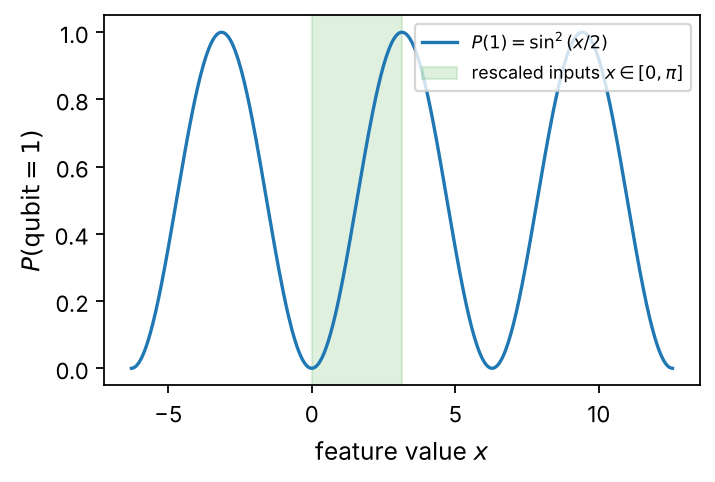

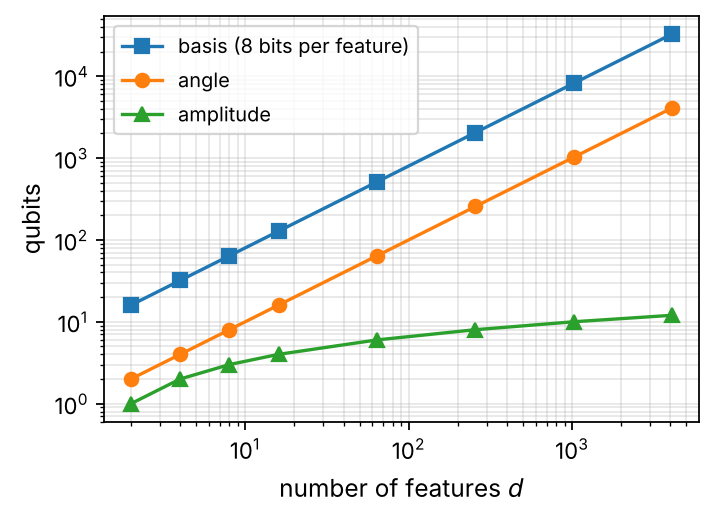

In [3]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter1/data_encodings.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter1').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))
